# Mejor modelo XGBoost Multicanal con MLflow

**Maestría en Inteligencia Artificial MAIA**

**Proyecto - Desarrollo de Soluciones**

***Estudiantes:***
- María José García (mj.garciab1@uniandes.edu.co)
- Daniel Osuna (d.osuna@uniandes.edu.co)
- Gabriel Vizcaya (g.vizcaya@uniandes.edu.co)
- Joel Vargas (js.vargasl1@uniandes.edu.co)

Entrena el mejor modelo XGBoost Multicanal encontrado en `08_model_xgboost.ipynb`, calcula metricas de evaluacion y registra el experimento en MLflow.

In [1]:
# Importe los conjuntos de datos procesados y separe variables predictoras y objetivo
import pandas as pd
import numpy as np
import seaborn as sns
import json
import tempfile
import mlflow
import mlflow.xgboost
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    classification_report,
)
from xgboost import XGBClassifier
from pathlib import Path
import sys
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))
from src.data.segmentation import CLASS_NAMES, INT_TO_CLASS

/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data" / "processed" / "train_multicanal.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
TRAIN_PATH = DATA_DIR / "train_multicanal.csv"
TEST_PATH = DATA_DIR / "test_multicanal.csv"

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

TARGET_COLUMN = "y"
ID_COLUMNS = ["recording_id", "subject_code"]
CONTROL_COLUMNS = ["split", "epoch_idx_in_recording"]
CATEGORICAL_COLUMNS = ["channel_combo"]


In [3]:
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

missing_columns = set(train_df.columns) ^ set(test_df.columns)
if missing_columns:
    raise ValueError(f"Train y test no tienen las mismas columnas: {missing_columns}")

excluded_columns = [TARGET_COLUMN, *ID_COLUMNS, *CONTROL_COLUMNS]
base_feature_columns = [
    column
    for column in train_df.columns
    if column not in excluded_columns
]
print(f"Columnas base: {base_feature_columns}")
print(f"Columnas excluidas: {excluded_columns}")

Columnas base: ['channel_combo', 'channel_count', 'has_eeg_pz_oz', 'has_eog_horizontal', 'EEG_Fpz-Cz__alpha_power_abs', 'EEG_Fpz-Cz__alpha_power_rel', 'EEG_Fpz-Cz__beta_power_abs', 'EEG_Fpz-Cz__beta_power_rel', 'EEG_Fpz-Cz__delta_alpha_ratio', 'EEG_Fpz-Cz__delta_power_abs', 'EEG_Fpz-Cz__delta_power_rel', 'EEG_Fpz-Cz__sef95', 'EEG_Fpz-Cz__sigma_power_abs', 'EEG_Fpz-Cz__sigma_power_rel', 'EEG_Fpz-Cz__spectral_entropy', 'EEG_Fpz-Cz__theta_alpha_ratio', 'EEG_Fpz-Cz__theta_power_abs', 'EEG_Fpz-Cz__theta_power_rel', 'EEG_Pz-Oz__alpha_power_abs', 'EEG_Pz-Oz__alpha_power_rel', 'EEG_Pz-Oz__beta_power_abs', 'EEG_Pz-Oz__beta_power_rel', 'EEG_Pz-Oz__delta_alpha_ratio', 'EEG_Pz-Oz__delta_power_abs', 'EEG_Pz-Oz__delta_power_rel', 'EEG_Pz-Oz__sef95', 'EEG_Pz-Oz__sigma_power_abs', 'EEG_Pz-Oz__sigma_power_rel', 'EEG_Pz-Oz__spectral_entropy', 'EEG_Pz-Oz__theta_alpha_ratio', 'EEG_Pz-Oz__theta_power_abs', 'EEG_Pz-Oz__theta_power_rel', 'EOG_horizontal__alpha_power_abs', 'EOG_horizontal__alpha_power_rel', '

In [4]:
test_df[TARGET_COLUMN].unique()

array(['W', 'N1', 'N2', 'N3', 'REM'], dtype=object)

In [5]:
X_train_raw = train_df[base_feature_columns].copy()
X_test_raw = test_df[base_feature_columns].copy()

# Codificación explícita de la combinación de canales. Esto permite que el modelo
# aprenda calibraciones distintas según disponibilidad de señales, manteniendo un
# único esquema de inferencia.
X_train = pd.get_dummies(X_train_raw, columns=CATEGORICAL_COLUMNS, dtype=np.int8)
X_test = pd.get_dummies(X_test_raw, columns=CATEGORICAL_COLUMNS, dtype=np.int8)
X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)

# Booleans a enteros para evitar problemas de serialización/tipos.
for df in (X_train, X_test):
    bool_columns = df.select_dtypes(include="bool").columns
    df[bool_columns] = df[bool_columns].astype(np.int8)

feature_columns = X_train.columns.tolist()

y_train_raw = train_df[TARGET_COLUMN]
y_test_raw = test_df[TARGET_COLUMN]

y_train_names = y_train_raw.map(INT_TO_CLASS).fillna(y_train_raw).astype(str)
y_test_names = y_test_raw.map(INT_TO_CLASS).fillna(y_test_raw).astype(str)

label_encoder = LabelEncoder()
label_encoder.fit(CLASS_NAMES)
y_train = label_encoder.transform(y_train_names)
y_test = label_encoder.transform(y_test_names)
class_labels = np.array(CLASS_NAMES)

sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

print(f"Train shape: {X_train.shape}")
print(f"Test shape: {X_test.shape}")
print(f"Numero de features: {len(feature_columns)}")
print(f"Clases: {class_labels.tolist()}")

Train shape: (601088, 49)
Test shape: (180828, 49)
Numero de features: 49
Clases: ['W', 'N1', 'N2', 'N3', 'REM']


In [6]:
# Defina el servidor, experimento y tag requerido para registrar la corrida
MLFLOW_TRACKING_URI = "http://32.194.151.154:5000"
MLFLOW_EXPERIMENT_NAME = "sleep-staging-baseline-multicanal"

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
experiment = mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)

print(f"Tracking URI: {MLFLOW_TRACKING_URI}")
print(f"Experiment: {experiment.name}")

Tracking URI: http://32.194.151.154:5000
Experiment: sleep-staging-baseline-multicanal


In [7]:
best_params = {
    "reg_lambda": 0.5,
    "reg_alpha": 0.5,
    "n_estimators": 700,
    "max_depth": 6,
    "learning_rate": 0.03,
    "gamma": 0.3,
}

fixed_params = {
    "objective": "multi:softprob",
    "num_class": len(class_labels),
    "eval_metric": "mlogloss",
    "tree_method": "hist",
    "random_state": 42,
    "n_jobs": -1,
}

display(pd.Series(best_params, name="best_params"))

reg_lambda         0.50
reg_alpha          0.50
n_estimators     700.00
max_depth          6.00
learning_rate      0.03
gamma              0.30
Name: best_params, dtype: float64

In [8]:
def save_confusion_matrix_plot(cm: list, class_names: list, out_path: str) -> None:
    cm = np.array(cm)
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(class_names)))
    ax.set_xticklabels(class_names)
    ax.set_yticks(range(len(class_names)))
    ax.set_yticklabels(class_names)
    ax.set_xticks(np.arange(-0.5, len(class_names), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(class_names), 1), minor=True)
    ax.grid(which="minor", color="black", linestyle="-", linewidth=1)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
    ax.set_title("Matriz de confusión -- Modelo avanzado (test)")
    thresh = cm.max() / 2 if cm.max() > 0 else 0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                     color="white" if cm[i, j] > thresh else "black")
    fig.colorbar(im)
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.close(fig)

In [14]:
with mlflow.start_run(experiment_id=experiment.experiment_id, run_name="xgboost_baseline_multicanal"):
    mlflow.set_tag("model_type", "baseline")
    mlflow.set_tag("signals_used", "EEG Fpz-Cz + EEG Pz-Oz + EOG horizontal")
    mlflow.set_tag("stage", "final_model")
    
    xgb_model = XGBClassifier(**fixed_params, **best_params)
    xgb_model.fit(X_train, y_train, sample_weight=sample_weights)

    y_pred = xgb_model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
    balanced_accuracy = balanced_accuracy_score(y_test, y_pred)
    cohens_kappa = cohen_kappa_score(y_test, y_pred)

    precision, recall, f1, support = precision_recall_fscore_support(
        y_test,
        y_pred,
        labels=label_encoder.transform(class_labels),
        zero_division=0,
    )

    per_class_metrics = pd.DataFrame(
        {
            "class": class_labels,
            "precision_per_class": precision,
            "recall_per_class": recall,
            "f1_per_class": f1,
            "support": support,
        }
    )

    conf_matrix = confusion_matrix(y_test, y_pred, labels=label_encoder.transform(class_labels))
    conf_matrix_df = pd.DataFrame(conf_matrix, index=class_labels, columns=class_labels)

    cm_path = "confusion_matrix_test.png"
    save_confusion_matrix_plot(conf_matrix_df, CLASS_NAMES, cm_path)
    #mlflow.log_artifact(cm_path)

    mlflow.log_params(best_params)
    mlflow.log_params({
        "num_class": len(class_labels),
        "n_features": len(feature_columns),
        "excluded_id_columns": ",".join(ID_COLUMNS),
        "excluded_control_columns": ",".join(CONTROL_COLUMNS),
        "categorical_columns": ",".join(CATEGORICAL_COLUMNS),
    })

    #mlflow.xgboost.log_model(xgb_model, name="best-xgboost-multicanal-model")

    mlflow.log_metric("accuracy", accuracy)
    mlflow.log_metric("macro_f1", macro_f1)
    mlflow.log_metric("balanced_accuracy", balanced_accuracy)
    mlflow.log_metric("cohens_kappa", cohens_kappa)

    print(f"accuracy: {accuracy:.4f}")
    print(f"macro_f1: {macro_f1:.4f}")
    print(f"balanced_accuracy: {balanced_accuracy:.4f}")
    print(f"cohens_kappa: {cohens_kappa:.4f}")
    display(per_class_metrics)
    display(conf_matrix_df)

accuracy: 0.7278
macro_f1: 0.6713
balanced_accuracy: 0.7139
cohens_kappa: 0.6334


,class,precision_per_class,recall_per_class,f1_per_class,support
0,W,0.881665,0.847888,0.864447,65544
1,N1,0.338121,0.485671,0.398682,20308
2,N2,0.895705,0.684504,0.775990,62156
3,N3,0.591928,0.915142,0.718876,9840
4,REM,0.564449,0.636466,0.598298,22980


,W,N1,N2,N3,REM
W,55574,6689,344,396,2541
N1,4006,9863,2686,120,3633
N2,1802,7104,42546,5595,5109
N3,154,22,656,9005,3
REM,1497,5492,1268,97,14626


🏃 View run xgboost_baseline_multicanal at: http://32.194.151.154:5000/#/experiments/5/runs/4a7712d0b58548d4a4134f059c2e4bc6
🧪 View experiment at: http://32.194.151.154:5000/#/experiments/5


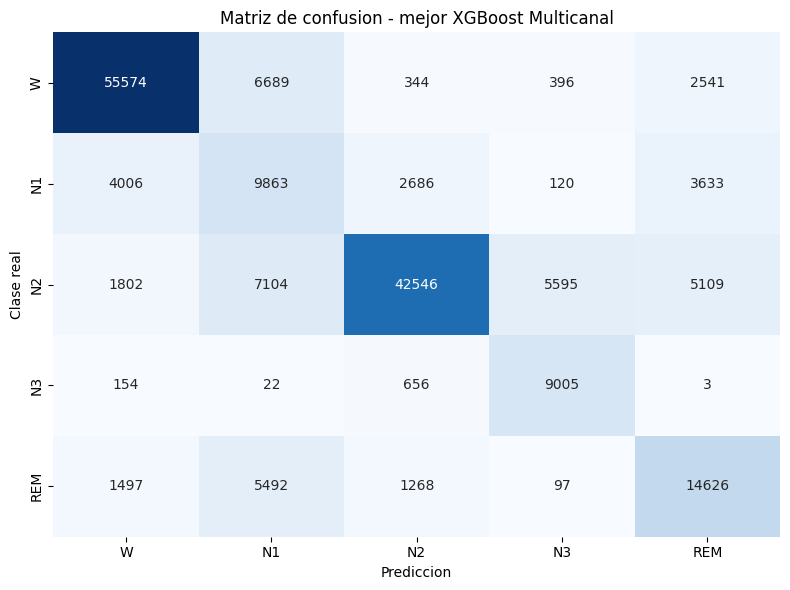

In [10]:
# Visualice la matriz de confusion despues de entrenar y predecir
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_df, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Matriz de confusion - mejor XGBoost Multicanal")
plt.xlabel("Prediccion")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

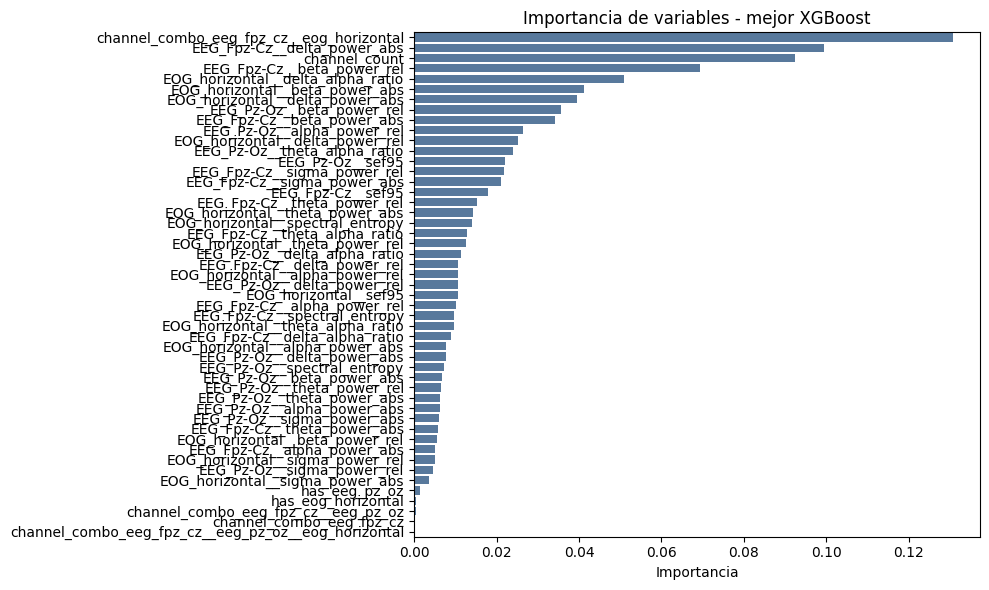

,feature,importance
48,channel_combo_eeg_fpz_cz__eog_horizontal,0.130774
8,EEG_Fpz-Cz__delta_power_abs,0.099389
0,channel_count,0.092415
6,EEG_Fpz-Cz__beta_power_rel,0.069255
35,EOG_horizontal__delta_alpha_ratio,0.050987
33,EOG_horizontal__beta_power_abs,0.041208
36,EOG_horizontal__delta_power_abs,0.039488
20,EEG_Pz-Oz__beta_power_rel,0.035563
5,EEG_Fpz-Cz__beta_power_abs,0.034252
18,EEG_Pz-Oz__alpha_power_rel,0.026345


In [11]:
feature_importance = pd.DataFrame(
    {
        "feature": feature_columns,
        "importance": xgb_model.feature_importances_,
    }
).sort_values("importance", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance, x="importance", y="feature", color="#4C78A8")
plt.title("Importancia de variables - mejor XGBoost")
plt.xlabel("Importancia")
plt.ylabel("")
plt.tight_layout()
plt.show()

display(feature_importance)